# 17_zenteno_single_sugar_variable_solubility

Copy of 17_zenteno_single_sugar.source.ipynb. Original files are preserved. Chemical model and preprocessing remain unchanged. Gas calibration below replaces the previous constant-solubility parameters.


## Variable CO₂ solubility and gas recalibration
Chemical parameters, samples, initial conditions, nutrient pulses and the 5–10 g/L activation are preserved. Only kLa and observation gain are fitted, independently for each chemical model. Training: LAB019–021; holdout: LAB016–018. The objective is ordinary MSE with equal weight per training LAB, using the original hourly RAW medians (not the Kalman-filter 30-minute means).

The empirical wine correlation reproduced as Eq. 1 in Liger-Belair et al. (2023), attributed there to Lonvaud-Funel and Matsumoto, is
\[
k_H=3.295\exp[(7\times10^{-5}a-0.02905)T-0.0179a-0.00111S],\qquad C_{sat}=k_Hp_{CO_2}.
\]
T is in °C, a is ethanol % vol, S is glucose + fructose in g/L, kH is in g/(L bar). Ethanol conversion uses a=E/7.8924, with pure ethanol density 789.24 g/L at 20°C as a reference conversion, not an evolving mixture density. Measured temperature and model-predicted ethanol/sugar vary throughout each batch. Coefficients are fixed; pCO2=1 bar is an explicit assumption, not a pressure measurement. Application to fermenting must is an extrapolation requiring validation, particularly at high sugar. Source: https://doi.org/10.1021/acsomega.3c01812 . The historical provisional correlation is not used.

The transfer law below is our adaptation, not an equation attributed to that paper:
\[
q_{eff}=Aq_{prod},\quad r_{abs}=\min(q_{eff},k_La\max(C_{sat}-C_d,0)),\quad
r_{des}=k_La\max(C_d-C_{sat},0),\quad
\dot C_d=r_{abs}-r_{des},\quad q_{gas}=q_{eff}-\dot C_d,\quad q_{pred}=gq_{gas}.
\]
This retains the previous absorption-limited reservoir and adds release above equilibrium. Cd is not clipped to changing saturation: supersaturation can persist and relax. Cd(0)=0 is retained. The same effective source activation is retained, so conservation applies to that source, not to unattenuated stoichiometric production. kLa is an effective coefficient in this adapted law, not an independently measured physical transfer coefficient.

Exact piecewise integration for interval-constant midpoint saturation and interval-mean production preserves positivity and concentration balance. Finite-volume mass checks include homogeneous withdrawals; gain is outside the balance. Positive fitting bounds are kLa=[0.001,20] h⁻¹, gain=[0.05,3], declared exploratory constraints. A log-spaced kLa profile with analytically optimized bounded gain, local refinement, bound checks and half-step verification is reported. Holdout never selects parameters.


## Ecuaciones y alcance
\[
\mu=\mu_0a_\mu(T)\frac{N}{N+K_N(T)},\qquad
\beta_S=\beta_{S0}a_\beta(T)\frac{S}{S+K_S(T)}\frac{K_{iE}(T)}{E+K_{iE}(T)}.
\]
\[
\dot X=(\mu-k_d)X,\quad \dot N=-\mu X/Y_{X/N},\quad
\dot S=-X[\mu/Y_{X/S}+\beta_S/Y_{E/S}+m(T)S/(S+1)],\quad \dot E=\beta_SX.
\]
Concentraciones en g/L, tiempo en horas; el 1 del factor de mantenimiento es 1 g/L, igual al módulo original. Se anula mu si S está agotado. Nutrición: salto instantáneo de N, muestra previa al salto si coincide.

Chemical parameters are fixed to their original executed values. The variable-solubility specification above replaces the old gas equations.


Pares de réplicas: 23 sigma réplica: 0.1189341469231937 sigmaX aplicada: 0.5
PARÁMETROS QUÍMICOS COMPLETOS {
  "mu0": 0.09403147367985473,
  "betaG0": 0.42243676903335664,
  "betaF0": 0.6236552480900203,
  "Kn0": 0.008257860224319971,
  "Kg0": 4.400775419123265,
  "Kf0": 19.296083508118652,
  "Kig0": 65.01993873457147,
  "Kie0": 96.26516563486751,
  "Kd0": 0.00044,
  "Yxn": 6.456225797038313,
  "Yxg": 0.9660935553477866,
  "Yxf": 1.1098958529485594,
  "Yeg": 0.4684585383875136,
  "Yef": 0.5113278649826252,
  "m0": 0.0183385793928771
}
Química fija: no se recalibra en esta prueba de activación.
GAS_FIT_JSON {"model": "G/F", "kLa": 0.15007991020720535, "gain": 0.6460643588058115, "training_MSE": 0.017269820343074855, "training": ["LAB019", "LAB020", "LAB021"], "holdout": ["LAB016", "LAB017", "LAB018"], "kLa_at_bound": false, "gain_at_bound": false}
GAS_CHECKS_JSON [{"LAB": "LAB019", "role": "Calibration", "RMSE": 0.11224019835409013, "mass_error_g": 7.93809462606987e-15, "half_step_max_e

,LAB,original_g_L,viables_millones_mL,corregido_g_L
0,LAB004,0.3939,10.75,0.3225
1,LAB005,0.4932,11.25,0.3375


Kn_Zenteno_g_L          0.010000
referencia_paper_C     23.000000
Kn0_codigo_g_L          0.008258
referencia_codigo_C    20.000000
Name: Kn fijo y conversión de referencia térmica, dtype: float64

Kn0     0.008258
Kg0     4.400775
Kf0    19.296084
Kd0     0.000440
Yxg     0.966094
Yxf     1.109896
m0      0.018339
Name: Fijos: theta_full salvo Kn y Kd0 de Zenteno, dtype: float64

,parametro,inicio,inicio_factible,minimo,maximo
0,mu0,0.078728,0.078728,0.05,1.0000
1,betaG0,0.428878,0.428878,0.10,10.0000
2,betaF0,3.440399,3.440399,0.10,10.0000
3,Kig0,17.845213,17.845213,5.00,1000.0000
4,Kie0,24.895476,24.895476,5.00,1000.0000
5,Yxn,3.734653,3.734653,1.00,100.0000
6,Yeg,0.250395,0.250395,0.10,0.5114
7,Yef,0.684927,0.511400,0.10,0.5114


,LAB,agotamiento_h,corte_YAN_h,N0_mg,pulsos,X,N,G,F,E
0,LAB004,91.0,103.0,230.76,"((68.5, 0.08),)",10,8,12,12,4
1,LAB005,91.0,103.0,227.30,"((68.5, 0.08),)",10,8,12,12,4
2,LAB006,122.0,134.0,229.12,"((100.0, 0.08),)",12,9,14,14,4
3,LAB007,88.0,100.0,239.04,"((65.5, 0.08),)",11,8,12,12,5
4,LAB008,88.0,100.0,239.22,"((65.5, 0.08),)",11,8,12,12,5
5,LAB009,64.0,76.0,237.40,"((41.84615384615385, 0.08),)",10,6,11,11,4


,LAB,t_h,original_mg,usado_mg,estado
0,LAB004,0.0,230.76,230.76,Inicial
1,LAB004,19.0,182.72,182.72,Usado
2,LAB004,26.0,157.42,157.42,Usado
3,LAB004,43.0,60.16,60.16,Usado
4,LAB004,50.0,19.00,0.00,Transformado
...,...,...,...,...,...
74,LAB009,88.0,17.00,NaN,Excluido
75,LAB009,96.0,19.00,NaN,Excluido
76,LAB009,120.0,5.00,NaN,Excluido
77,LAB009,144.0,25.00,NaN,Excluido


,LAB,X,N,G,F,E,pulsos,corte_h
0,LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08648648648648648),)",166.000000
1,LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08888888888888889),)",172.333333
2,LAB021,0.270000,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08648648648648648),)",166.000000
3,LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)",151.100000
4,LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.28),)",141.000000
5,LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)",141.000000


,kLa,gain,MSE
0,0.001000,0.638249,0.018350
1,0.001167,0.638504,0.018343
2,0.001363,0.638795,0.018335
3,0.001591,0.639126,0.018325
4,0.001857,0.639501,0.018315
...,...,...,...
61,10.769998,0.641676,0.017806
62,12.572430,0.641774,0.017803
63,14.676510,0.641860,0.017800
64,17.132723,0.641931,0.017798


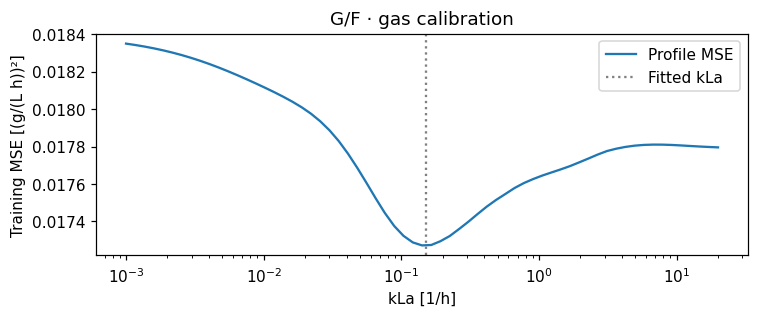

,LAB,role,RMSE,mass_error_g,half_step_max_error,Csat_min,Csat_max,produced_g,emitted_g,removed_g,final_dissolved_g
0,LAB019,Calibration,0.112240,7.938095e-15,3.156998e-06,1.481959,1.836705,121.609536,118.694314,0.365925,2.549296
1,LAB020,Calibration,0.074421,-1.554312e-15,4.303273e-07,1.613971,1.729750,118.751369,115.648724,0.332260,2.770385
2,LAB021,Calibration,0.183502,3.719247e-15,7.793893e-07,1.448400,1.625336,125.539605,122.439798,0.359465,2.740343
3,LAB016,Holdout,0.135665,0.000000e+00,2.788553e-07,1.504917,1.575170,146.495572,143.373809,0.000000,3.121763
4,LAB017,Holdout,0.134385,2.842171e-14,4.247397e-07,1.508751,1.572785,145.100865,141.976692,0.000000,3.124172
5,LAB018,Holdout,0.122654,0.000000e+00,4.124214e-07,1.504580,1.576138,146.502755,143.380183,0.000000,3.122572


,LAB,rol,n,RMSE,sesgo
0,LAB019,Calibración gas,166,0.112240,0.012932
1,LAB020,Calibración gas,172,0.074421,0.031482
2,LAB021,Calibración gas,166,0.183502,0.017241
3,LAB016,Holdout gas,152,0.135665,0.000533
4,LAB017,Holdout gas,141,0.134385,-0.037669
5,LAB018,Holdout gas,141,0.122654,-0.012401


,RMSE,sesgo
rol,,
Calibración gas,0.123388,0.020552
Holdout gas,0.130901,-0.016512


,LAB,inicio_5g_h,completa_10g_h
0,LAB019,11.9,19.9
1,LAB020,20.6,32.2
2,LAB021,10.9,17.7
3,LAB016,7.7,13.3
4,LAB017,7.9,13.5
5,LAB018,7.7,13.3


In [1]:
from pathlib import Path
from dataclasses import replace
import sys,json,hashlib,math,time
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares,minimize_scalar
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
assert Path(sys.prefix).name.lower()=='fermentation'
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation import model as kin
from wine_fermentation.data import natural_batches
from wine_fermentation.models.historical.calibration import load
from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
NAME='17_zenteno_single_sugar_variable_solubility'
protected=[p for folder in ['src','configs','data/compatibility/chemistry','data/cleaned/natural/lab004_009','notebooks'] for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and '_variable_solubility.' not in p.name]
hashes={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
data,training,profiles=natural_batches(ROOT)
# Correcciones de recuento inicial indicadas por el usuario; originales conservados.
INITIAL_VIABLE_MCELLS_ML={'LAB004':10.75,'LAB005':11.25}
initial_biomass_audit=[];corrected_training=[]
for batch in training:
 if batch.batch in INITIAL_VIABLE_MCELLS_ML:
  count=INITIAL_VIABLE_MCELLS_ML[batch.batch];x0=count*.03
  ids=np.flatnonzero(np.isclose(batch.time,0.));assert len(ids)==1
  obs0={k:v.copy() for k,v in batch.observations.items()};obs0['X'][ids[0]]=x0
  initial_biomass_audit.append(dict(LAB=batch.batch,original_g_L=batch.initials['X'],viables_millones_mL=count,corregido_g_L=x0))
  batch=replace(batch,initials={**batch.initials,'X':x0},observations=obs0)
  mask=data.batch.eq(batch.batch)&np.isclose(data.time_h,0.)
  assert mask.sum()==1
  data.loc[mask,'X_viable_kg_m3']=x0;data.loc[mask,'X_viable_mcells_ml']=count
  assert batch.initials['X']==batch.observations['X'][ids[0]]
 corrected_training.append(batch)
training=corrected_training
assert len(initial_biomass_audit)==2
display(pd.DataFrame(initial_biomass_audit))

start=kin.normalize_parameters(json.loads((ROOT/'configs/theta/theta_full.json').read_text()))
config=json.loads((ROOT/'configs/models/without_transporters/calibration.json').read_text())
# Tabla 2 de Zenteno: Kn=0.01 g/L a23C; nuestro Kn0 se referencia a20C.
KN_ZENTENO_G_L=0.01;KN_PAPER_REF_K=296.15;KN_CODE_REF_K=293.15
KN_THERMAL_FACTOR=np.exp(kin.FIXED_CONSTANTS['EaKn']*(KN_PAPER_REF_K-KN_CODE_REF_K)/(KN_CODE_REF_K*kin.FIXED_CONSTANTS['R']*KN_PAPER_REF_K))
start['Kn0']=KN_ZENTENO_G_L/KN_THERMAL_FACTOR
KD0_ZENTENO_H=0.00044
start['Kd0']=KD0_ZENTENO_H
assert np.isclose(start['Kn0']*KN_THERMAL_FACTOR,KN_ZENTENO_G_L,rtol=1e-14)
display(pd.Series(dict(Kn_Zenteno_g_L=KN_ZENTENO_G_L,referencia_paper_C=23,Kn0_codigo_g_L=start['Kn0'],referencia_codigo_C=20),name='Kn fijo y conversión de referencia térmica'))
names=[k for k in config['bounds'] if k not in ['aN','KNa','Kn0','Kd0']]
assert len(names)==8 and 'Kn0' not in names and 'Kd0' not in names
bounds={k:config['bounds'][k] for k in names};lo,hi=np.array(list(bounds.values())).T
fixed={k:v for k,v in start.items() if k not in names}
display(pd.Series(fixed,name='Fijos: theta_full salvo Kn y Kd0 de Zenteno'))
display(pd.DataFrame([dict(parametro=k,inicio=start[k],inicio_factible=np.clip(start[k],lo[i]+1e-10,hi[i]-1e-10),minimo=lo[i],maximo=hi[i]) for i,k in enumerate(names)]))


diffs=[]
bylab={b.batch:b for b in training}
for a,b in [('LAB004','LAB005'),('LAB007','LAB008')]:
 aa=pd.Series(bylab[a].observations['X'],index=bylab[a].time);bb=pd.Series(bylab[b].observations['X'],index=bylab[b].time)
 z=pd.concat([aa,bb],axis=1).dropna();diffs.extend((z.iloc[:,0]-z.iloc[:,1]).tolist())
sigma_rep=float(np.sqrt(np.mean(np.square(diffs)))/np.sqrt(2));SIGMA_X=max(.5,3*sigma_rep)
assert len(diffs)>0
print('Pares de réplicas:',len(diffs),'sigma réplica:',sigma_rep,'sigmaX aplicada:',SIGMA_X)
treated=[];audit=[];rules=[]
for b in training:
 obs={k:v.copy() for k,v in b.observations.items()};old=obs['N'].copy()
 obs['N'][np.isfinite(old)&(old<=.020)]=0
 if b.batch=='LAB006':
  ids=np.flatnonzero(np.isclose(b.time,122)&np.isfinite(old));assert len(ids)==1 and np.isclose(old[ids[0]],.027)
  obs['N'][ids]=0;depletion=122.
 else:
  last=max(t for t,d in b.pulses['N']);ids=np.flatnonzero((b.time>=last)&np.isfinite(obs['N'])&(obs['N']==0));assert len(ids)
  depletion=float(b.time[ids[0]])
 obs['N'][b.time>depletion+12]=np.nan
 for i in np.flatnonzero(np.isfinite(old)):
  audit.append(dict(LAB=b.batch,t_h=b.time[i],original_mg=old[i]*1000,usado_mg=obs['N'][i]*1000,estado='Inicial' if b.time[i]==0 else ('Excluido' if not np.isfinite(obs['N'][i]) else ('Transformado' if old[i]!=obs['N'][i] else 'Usado'))))
 assert all(np.array_equal(obs[k],b.observations[k],equal_nan=True) for k in obs if k!='N')
 treated.append(replace(b,observations=obs))
 rules.append(dict(LAB=b.batch,agotamiento_h=depletion,corte_YAN_h=depletion+12,N0_mg=b.initials['N']*1000,pulsos=b.pulses['N'],**{k:int(np.count_nonzero(np.isfinite(obs[k])&(b.time>0))) for k in obs}))
audit=pd.DataFrame(audit);display(pd.DataFrame(rules));display(audit)
def sigma(state,y):return np.full_like(y,SIGMA_X) if state=='X' else kin.sigma_for_state(state,y)
def simulate(b,p):
 def rhs(t,y):
  out=np.asarray(kin.rhs(t,y,p,b))
  if y[2]<=0 or y[3]<=0:
   q=kin.kinetic_terms(p,kin.temperature_at(b,t),*y);growth=q['mu']*max(float(y[0]),0)
   out[0]-=growth;out[1]+=growth/p['Yxn'];out[2]+=growth/p['Yxg'];out[3]+=growth/p['Yxf']
  return out
 # Muestra previa al salto si coincide con la nutrición; dosis completa después.
 minimum=np.full(5,np.inf);jumps=[];events={}
 for tp,dose in b.pulses.get('N',()):
  assert tp>float(b.time[0]) and dose>=0,'No se admiten pulsos iniciales extra'
  if tp<=b.time[-1]:events[float(tp)]=events.get(float(tp),0.)+float(dose)
 times=np.asarray(b.time);state=kin.initial_vector(b);records={float(times[0]):state.copy()};now=float(times[0])
 for end in sorted(set([float(times[-1])]+list(events))):
  requested=times[(times>now)&(times<=end)]
  sol=solve_ivp(rhs,(now,end),state,t_eval=np.unique(np.r_[requested,end]),method='LSODA',rtol=2e-6,atol=2e-8,max_step=.5)
  if not sol.success or not np.isfinite(sol.y).all() or np.any(sol.y.min(axis=1)<-np.array([1e-6,1e-6,1e-4,1e-4,1e-6])):raise RuntimeError('Integración química inválida '+b.batch+' '+str(sol.message)+' mínimos='+str(dict(zip(kin.STATE_NAMES,sol.y.min(axis=1)))))
  minimum=np.minimum(minimum,sol.y.min(axis=1))
  records.update({float(t):y.copy() for t,y in zip(sol.t,sol.y.T)});state=sol.y[:,-1].copy();now=end
  if end in events:
   before=state.copy();state[1]+=events[end]
   assert np.isclose(state[1]-before[1],events[end],atol=1e-12) and np.array_equal(state[[0,2,3,4]],before[[0,2,3,4]])
   jumps.append(dict(t=end,dose=events[end],before=before.copy(),after=state.copy()))
 f=pd.DataFrame(np.maximum(np.vstack([records[float(t)] for t in times]),0),index=times,columns=kin.STATE_NAMES);f['GF']=f.G+f.F
 f.attrs['minimum_integrated_states']=dict(zip(kin.STATE_NAMES,minimum.tolist()))
 f.attrs['pulse_jumps']=jumps
 assert np.isclose(sum(j['dose'] for j in jumps),sum(events.values()),atol=1e-12)
 return f

def with_jumps(f):
 extra=[];tt=[]
 for j in f.attrs['pulse_jumps']:
  if j['t'] not in f.index:extra.append(j['before']);tt.append(j['t'])
  extra.append(j['after']);tt.append(j['t'])
 if not extra:return f
 added=pd.DataFrame(extra,index=tt,columns=kin.STATE_NAMES);added['GF']=added.G+added.F
 return pd.concat([f,added]).sort_index(kind='stable')

support=[(b,s,np.isfinite(b.observations[s])&(b.time>0)) for b in treated for s in kin.STATE_NAMES]
NR=sum(m.sum() for b,s,m in support);calls=0;rejected=0


# Química congelada de la recalibración anterior; sin optimización en esta prueba.
theta={'mu0': 0.09403147367985473, 'betaG0': 0.42243676903335664, 'betaF0': 0.6236552480900203, 'Kn0': 0.008257860224319971, 'Kg0': 4.400775419123265, 'Kf0': 19.296083508118652, 'Kig0': 65.01993873457147, 'Kie0': 96.26516563486751, 'Kd0': 0.00044, 'Yxn': 6.456225797038313, 'Yxg': 0.9660935553477866, 'Yxf': 1.1098958529485594, 'Yeg': 0.4684585383875136, 'Yef': 0.5113278649826252, 'm0': 0.0183385793928771}
assert theta['Kn0']==start['Kn0'] and theta['Kd0']==KD0_ZENTENO_H
assert all(theta[k]==v for k,v in fixed.items())
print('PARÁMETROS QUÍMICOS COMPLETOS',json.dumps(theta,indent=2))
print('Química fija: no se recalibra en esta prueba de activación.')
traincurves={b.batch:simulate(b,theta) for b in treated}


v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018'];TRAIN=LABS[:3];HOLD=LABS[3:]
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h']);obs=observations(raw)
batches={};cores={};volumes={};caches={};activation={};entry=[]
for lab in LABS:
 b=v.batches[lab];ev=raw.loc[raw.lab.eq(lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h');et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
 def volume(t,et=et,vv=vv):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
 volumes[lab]=volume
 if lab in TRAIN:b=replace(b,pulses={**b.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])})
 if lab=='LAB017':b=replace(b,pulses={**b.pulses,'N':((min(t for t,d in b.pulses['N']),sum(d for t,d in b.pulses['N'])),)})
 if lab=='LAB021':b=replace(b,initials={**b.initials,'X':9.*.03})
 batches[lab]=b;f=simulate(b,theta);cores[lab]=f;f=with_jumps(f)
 tt=np.unique(np.r_[np.arange(0,float(f.index[-1]),.1),f.index[-1]])
 rates=[]
 for t in tt:
  y=[np.interp(t,f.index,f[s]) for s in kin.STATE_NAMES];q=kin.kinetic_terms(theta,kin.temperature_at(b,t),*y)
  if y[2]<=0 or y[3]<=0:q['mu']=0.
  rates.append((q['mu']/12.72+(q['beta_g']+q['beta_f'])/1.05)*y[0])
 caches[lab]=(tt,np.asarray(rates))
 consumed=b.initials['G']+b.initials['F']-np.interp(tt,f.index,f.GF)
 z=np.clip((consumed-5.)/5.,0.,1.);activation[lab]=z*z*(3.-2.*z)
 assert np.all(activation[lab][consumed<=5.]==0) and np.all(activation[lab][consumed>=10.]==1)
 entry.append(dict(LAB=lab,**b.initials,pulsos=b.pulses['N'],corte_h=v.horizons[lab]))
 obs[lab]=obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy()
display(pd.DataFrame(entry))

PCO2_BAR=1.0
ETHANOL_G_L_PER_VOL_PERCENT=7.8924
GAS_BOUNDS={'kLa':(0.001,20.),'gain':(.05,3.)}
GAS_INITIAL=(0.07467887635557982,0.635238911849421)
gas_fits={}

def saturation(T,E,S):
 a=np.maximum(E,0)/ETHANOL_G_L_PER_VOL_PERCENT
 return 3.295*np.exp((7e-5*a-.02905)*np.asarray(T)-.0179*a-.00111*np.maximum(S,0))*PCO2_BAR

def configure_gas(frames,single=False):
 global gas_equilibrium
 gas_equilibrium={}
 for lab,f in frames.items():
  times=caches[lab][0]
  ff=plotframe_s(f) if single else with_jumps(f)
  T=np.array([kin.temperature_at(batches[lab],float(t)) for t in times])
  E=np.interp(times,ff.index,ff.E)
  S=np.interp(times,ff.index,ff.S if single else ff.GF)
  gas_equilibrium[lab]=(T,E,S,saturation(T,E,S))

def gas(lab,k,gain=1,activated=True,substeps=1):
 t,source=caches[lab]
 source=source*activation[lab] if activated else source.copy()
 T,E,S,sat=gas_equilibrium[lab]
 cd=np.zeros(len(t));qout=np.zeros(len(t));acc=np.zeros(len(t))
 qout[0]=max(source[0]-k*sat[0],0.)
 for i,dt in enumerate(np.diff(t),1):
  qp=(source[i-1]+source[i])/2;previous=cd[i-1];current=previous
  for j in range(substeps):
   h=dt/substeps;fraction=(j+.5)/substeps;cs=sat[i-1]*(1-fraction)+sat[i]*fraction
   if current>cs:
    current=cs+(current-cs)*np.exp(-k*h)
   else:
    D=cs-current
    if qp<=0 or D<=0:delta=0.
    elif k*D<=qp:delta=D*(-np.expm1(-k*h))
    else:
     crossing=(D-qp/k)/qp;linear=min(h,crossing);delta=qp*linear
     if crossing<h:delta+=(qp/k)*(-np.expm1(-k*(h-crossing)))
    current+=delta
  cd[i]=current;acc[i]=(current-previous)/dt;qout[i]=qp-acc[i]
 assert cd.min()>=-1e-12 and qout.min()>-1e-10
 assert np.max(abs(np.diff(cd)-np.diff(t)*((source[:-1]+source[1:])/2-qout[1:])))<1e-10
 return pd.DataFrame(dict(qprod=source,Cd=cd,Csat=sat,T=T,E=E,S=S,qgas=qout,qpred=gain*qout),index=t)

def calibrate_gas(model):
 # Analytic gain eliminates a redundant numerical search direction.
 def evaluate(logk,details=False):
  k=float(np.exp(logk));xy=xx=0.;pairs=[]
  for lab in TRAIN:
   f=gas(lab,k);o=obs[lab];x=np.interp(o.time_h,f.index,f.qgas);y=o.co2_raw_g_l_h.to_numpy()
   xx+=float(np.mean(x*x));xy+=float(np.mean(x*y));pairs.append((x,y))
  g=float(np.clip(xy/xx,*GAS_BOUNDS['gain']))
  objective=float(np.mean([np.mean((g*x-y)**2) for x,y in pairs]))
  return (objective,k,g) if details else objective
 grid=np.unique(np.r_[np.linspace(*np.log(GAS_BOUNDS['kLa']),65),np.log(GAS_INITIAL[0])])
 values=np.array([evaluate(x) for x in grid]);candidates=[evaluate(grid[0],True),evaluate(grid[-1],True)]
 for i in range(1,len(grid)-1):
  if values[i]<=values[i-1] and values[i]<=values[i+1]:
   result=minimize_scalar(evaluate,bounds=(grid[i-1],grid[i+1]),method='bounded',options={'xatol':1e-7})
   assert result.success
   candidates.append(evaluate(result.x,True))
 objective,k,g=min(candidates)
 profile=pd.DataFrame([dict(kLa=np.exp(x),gain=evaluate(x,True)[2],MSE=y) for x,y in zip(grid,values)])
 record=dict(model=model,kLa=k,gain=g,training_MSE=objective,training=TRAIN,holdout=HOLD,
             kLa_at_bound=bool(np.isclose(k,GAS_BOUNDS['kLa'][0]) or np.isclose(k,GAS_BOUNDS['kLa'][1])),
             gain_at_bound=bool(np.isclose(g,GAS_BOUNDS['gain'][0]) or np.isclose(g,GAS_BOUNDS['gain'][1])))
 gas_fits[model]=record
 print('GAS_FIT_JSON',json.dumps(record));display(profile)
 fig,ax=plt.subplots(figsize=(7,3));ax.semilogx(profile.kLa,profile.MSE,label='Profile MSE');ax.axvline(k,c='gray',ls=':',label='Fitted kLa')
 ax.set(xlabel='kLa [1/h]',ylabel='Training MSE [(g/(L h))²]',title=model+' · gas calibration');ax.legend(loc='best');fig.tight_layout();plt.show()
 checks=[]
 for lab in LABS:
  f=gas(lab,k,g);fine=gas(lab,k,g,substeps=2);tt=f.index.to_numpy();dt=np.diff(tt);V=volumes[lab](tt);cd=f.Cd.to_numpy();src=f.qprod.to_numpy()
  produced=np.sum(V[:-1]*dt*(src[:-1]+src[1:])/2);emitted=np.sum(V[:-1]*dt*f.qgas.to_numpy()[1:]);removed=np.sum((V[:-1]-V[1:])*cd[1:])
  error=V[-1]*cd[-1]-V[0]*cd[0]-produced+emitted+removed
  assert abs(error)<1e-8
  o=obs[lab];err=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h.to_numpy()
  coarse_obs=np.interp(o.time_h,f.index,f.qpred);fine_obs=np.interp(o.time_h,fine.index,fine.qpred)
  step_error=float(np.max(abs(coarse_obs-fine_obs)))
  assert step_error<.005,('Time-step sensitivity',lab,step_error)
  checks.append(dict(LAB=lab,role='Calibration' if lab in TRAIN else 'Holdout',RMSE=float(np.sqrt(np.mean(err**2))),mass_error_g=float(error),half_step_max_error=step_error,Csat_min=float(f.Csat.min()),Csat_max=float(f.Csat.max()),produced_g=float(produced),emitted_g=float(emitted),removed_g=float(removed),final_dissolved_g=float(V[-1]*cd[-1])))
 display(pd.DataFrame(checks));print('GAS_CHECKS_JSON',json.dumps(checks))
 return k,g

configure_gas(cores)
KLA,GAIN=calibrate_gas('G/F')

curves={lab:gas(lab,KLA,GAIN) for lab in LABS};metrics=[]
for lab in LABS:
 o=obs[lab];f=curves[lab];e=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h
 metrics.append(dict(LAB=lab,rol='Calibración gas' if lab in TRAIN else 'Holdout gas',n=len(o),RMSE=np.sqrt(np.mean(e*e)),sesgo=np.mean(e)))
metrics=pd.DataFrame(metrics);display(metrics);display(metrics.groupby('rol')[['RMSE','sesgo']].mean())

display(pd.DataFrame([dict(LAB=lab,inicio_5g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>0)[0]]),completa_10g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>=1)[0]])) for lab in LABS]))


Soporte de ajuste
GAS_FIT_JSON {"model": "S", "kLa": 0.13796553316180868, "gain": 0.6586783889606775, "training_MSE": 0.018627427255287904, "training": ["LAB019", "LAB020", "LAB021"], "holdout": ["LAB016", "LAB017", "LAB018"], "kLa_at_bound": false, "gain_at_bound": false}
GAS_CHECKS_JSON [{"LAB": "LAB019", "role": "Calibration", "RMSE": 0.12251476049224734, "mass_error_g": 1.4099832412739488e-14, "half_step_max_error": 2.7308342320786494e-06, "Csat_min": 1.4819901379342015, "Csat_max": 1.8360326332075438, "produced_g": 121.63885239733284, "emitted_g": 118.72607105106923, "removed_g": 0.3692260953602896, "final_dissolved_g": 2.543555250903333}, {"LAB": "LAB020", "role": "Calibration", "RMSE": 0.0743889651044376, "mass_error_g": -8.992806499463768e-15, "half_step_max_error": 3.7003485342523845e-07, "Csat_min": 1.61288899631366, "Csat_max": 1.72840884999847, "produced_g": 119.00846702167499, "emitted_g": 115.90351486408616, "removed_g": 0.33429230339524973, "final_dissolved_g": 2.7706598

,LAB,estado,n
0,LAB004,X,10
1,LAB004,N,8
2,LAB004,S,12
3,LAB004,E,4
4,LAB005,X,10
5,LAB005,N,8
6,LAB005,S,12
7,LAB005,E,4
8,LAB006,X,12
9,LAB006,N,9


mu0        0.090851
betaS0     0.818966
Ks0       23.046565
Kie0      96.265166
Yxn        6.497332
Yes        0.489318
Name: Fixed S chemical parameters, dtype: float64

,kLa,gain,MSE
0,0.001000,0.649325,0.019931
1,0.001167,0.649600,0.019922
2,0.001363,0.649915,0.019912
3,0.001591,0.650273,0.019901
4,0.001857,0.650679,0.019888
...,...,...,...
61,10.769998,0.653427,0.019226
62,12.572430,0.653507,0.019225
63,14.676510,0.653577,0.019225
64,17.132723,0.653636,0.019224


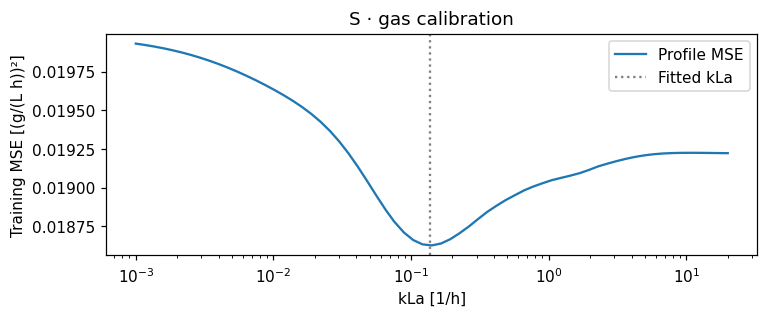

,LAB,role,RMSE,mass_error_g,half_step_max_error,Csat_min,Csat_max,produced_g,emitted_g,removed_g,final_dissolved_g
0,LAB019,Calibration,0.122515,1.409983e-14,2.730834e-06,1.481990,1.836033,121.638852,118.726071,0.369226,2.543555
1,LAB020,Calibration,0.074389,-8.992806e-15,3.700349e-07,1.612889,1.728409,119.008467,115.903515,0.334292,2.770660
2,LAB021,Calibration,0.187986,-2.348122e-14,6.826350e-07,1.448167,1.625584,125.247095,122.146893,0.359462,2.740741
3,LAB016,Holdout,0.141586,0.000000e+00,2.406540e-07,1.504902,1.575452,146.202119,143.079730,0.000000,3.122388
4,LAB017,Holdout,0.138341,2.842171e-14,3.659549e-07,1.508660,1.572489,144.771554,141.646822,0.000000,3.124733
5,LAB018,Holdout,0.128754,0.000000e+00,3.564953e-07,1.504573,1.576517,146.216042,143.092840,0.000000,3.123202


,kLa,gain,MSE
0,0.001000,0.635403,0.020405
1,0.001167,0.635661,0.020398
2,0.001363,0.635955,0.020389
3,0.001591,0.636289,0.020380
4,0.001857,0.636669,0.020369
...,...,...,...
61,10.769998,0.639675,0.019704
62,12.572430,0.639761,0.019703
63,14.676510,0.639836,0.019701
64,17.132723,0.639900,0.019699


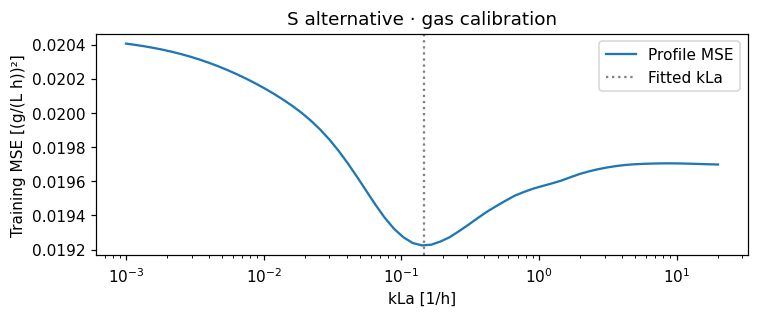

,LAB,role,RMSE,mass_error_g,half_step_max_error,Csat_min,Csat_max,produced_g,emitted_g,removed_g,final_dissolved_g
0,LAB019,Calibration,0.127437,1.626477e-14,3.034623e-06,1.481708,1.835687,121.686299,118.767289,0.368624,2.550386
1,LAB020,Calibration,0.057991,-3.724798e-14,4.127833e-07,1.613053,1.728731,119.348555,116.244851,0.334168,2.769535
2,LAB021,Calibration,0.195113,-2.253753e-14,7.516191e-07,1.447933,1.625106,125.133501,122.034913,0.358226,2.740362
3,LAB016,Holdout,0.122511,0.000000e+00,2.680183e-07,1.504845,1.574523,145.910620,142.788368,0.000000,3.122252
4,LAB017,Holdout,0.125269,-2.842171e-14,3.802527e-06,1.508429,1.571266,144.708453,141.583408,0.000000,3.125044
5,LAB018,Holdout,0.117174,0.000000e+00,3.967263e-07,1.504546,1.576229,145.939091,142.816066,0.000000,3.123025


,Kie libre previo,Kie fijo nuevo
mu0,0.089347,0.090851
betaS0,0.779052,0.818966
Ks0,51.793276,23.046565
Kie0,999.989454,96.265166
Yxn,6.193688,6.497332
Yes,0.489320,0.489318


In [2]:

# Referencia original guardada antes de construir el modelo reducido.
original_theta=theta.copy();original_train=traincurves.copy();original_cores=cores.copy();original_gas=curves.copy();original_gas_parameters=(KLA,GAIN)
YXS=1/(1/theta['Yxg']+1/theta['Yxf']);STATES=['X','N','S','E']
PARAMS=['mu0','betaS0','Ks0','Kie0','Yxn','Yes']
LOW=np.array([.05,.1,.1,5.,1.,.1]);HIGH=np.array([1.,20.,200.,1000.,100.,.5114])
pinit=np.array([theta['mu0'],theta['betaG0']+theta['betaF0'],10.,theta['Kie0'],theta['Yxn'],.49])
def terms_s(t,y,p,b):
 x,n,s,e=np.maximum(y,0);tk=kin.temperature_at(b,t)+273.15;R=kin.FIXED_CONSTANTS['R']
 ak=np.exp(46055*(tk-293.15)/(293.15*R*tk))
 mu=p['mu0']*np.exp(59453*(tk-300)/(300*R*tk))*n/(n+theta['Kn0']*ak+1e-8) if s>0 else 0.
 beta=p['betaS0']*np.exp(11000*(tk-296.15)/(296.15*R*tk))*s/(s+p['Ks0']*ak+1e-8)*(p['Kie0']*(ak+1e-8)/(e+p['Kie0']*(ak+1e-8)))
 td=-.0001*e**3+.0049*e**2-.1279*e+315.89
 kd=theta['Kd0']*np.exp(.0415*e+130000*(tk-305.65)/(305.65*R*tk)) if tk>=td else 0.
 maint=theta['m0']*np.exp(37681*(tk-293.3)/(293.3*R*tk))*s/(s+kin.MAINTENANCE_SUGAR_CUTOFF_KG_M3)
 return mu,beta,kd,maint

def simulate_s(b,p):
 def rhs(t,y):
  x=max(y[0],0);mu,be,kd,m=terms_s(t,y,p,b)
  return [(mu-kd)*x,-mu*x/p['Yxn'],-(mu/YXS+be/p['Yes']+m)*x,be*x]
 tt=np.asarray(b.time);y=np.array([b.initials['X'],b.initials['N'],b.initials['G']+b.initials['F'],b.initials['E']]);now=tt[0];rec={now:y.copy()};events={};jumps=[];minimum=y.copy()
 for t,d in b.pulses.get('N',()):
  assert t>now and d>=0
  if t<=tt[-1]:events[t]=events.get(t,0)+d
 for end in sorted(set([float(tt[-1])]+list(events))):
  requested=np.unique(np.r_[tt[(tt>now)&(tt<=end)],end])
  sol=solve_ivp(rhs,(now,end),y,t_eval=requested,method='LSODA',rtol=2e-6,atol=2e-8,max_step=.5)
  if not sol.success or not np.isfinite(sol.y).all() or np.any(sol.y.min(axis=1)<-np.array([1e-6,1e-6,1e-4,1e-6])):raise RuntimeError('Integración inválida '+b.batch)
  minimum=np.minimum(minimum,sol.y.min(axis=1));rec.update({float(t):z.copy() for t,z in zip(sol.t,sol.y.T)})
  y=sol.y[:,-1].copy();now=end
  if end in events:
   before=y.copy();y[1]+=events[end];jumps.append((end,before,y.copy()))
 f=pd.DataFrame(np.maximum([rec[float(t)] for t in tt],0),index=tt,columns=STATES)
 f.attrs['jumps']=jumps;f.attrs['minima']=minimum;return f

def plotframe_s(f):
 rows=[];times=[]
 for t,before,after in f.attrs['jumps']:
  rows.extend([before,after]);times.extend([t,t])
 return pd.concat([f,pd.DataFrame(rows,index=times,columns=STATES)]).sort_index(kind='stable') if rows else f

def targets(b,s):
 y=b.observations[s] if s!='S' else b.observations['G']+b.observations['F']
 sig=sigma(s,y) if s!='S' else np.hypot(kin.sigma_for_state('G',b.observations['G']),kin.sigma_for_state('F',b.observations['F']))
 return y,sig,np.isfinite(y)&(b.time>0)
support_s=[(b,s,*targets(b,s)) for b in treated for s in STATES]
NR_S=sum(mask.sum() for b,s,y,sg,mask in support_s);rejections=0
print('Soporte de ajuste');display(pd.DataFrame([dict(LAB=b.batch,estado=s,n=int(mask.sum())) for b,s,y,sg,mask in support_s]))
def residual_s(logp):
 global rejections
 p=dict(zip(PARAMS,np.exp(logp)))
 try:
  predictions={b.batch:simulate_s(b,p) for b in treated}
  return np.concatenate([(predictions[b.batch][s].to_numpy()[mask]-y[mask])/sg[mask] for b,s,y,sg,mask in support_s])
 except RuntimeError:
  rejections+=1;return np.full(NR_S,1e5)
ps_free={'mu0':0.08934685518404714,'betaS0':0.7790518060881909,'Ks0':51.79327570452845,'Kie0':999.9894538748339,'Yxn':6.193688479843567,'Yes':0.4893196389269888}
FREE_PARAMS=[k for k in PARAMS if k!='Kie0'];SELECT=[PARAMS.index(k) for k in FREE_PARAMS];KIE_FIXED=original_theta['Kie0']
LOW_FREE=LOW[SELECT];HIGH_FREE=HIGH[SELECT]
def expand_fixed(logp):
 p=dict(zip(FREE_PARAMS,np.exp(logp)));p['Kie0']=KIE_FIXED
 return np.log([p[k] for k in PARAMS])
def residual_fixed(logp):return residual_s(expand_fixed(logp))
# Frozen chemical parameters from the original executed notebook; gas-only recalibration.
ps={'mu0': 0.09085058816701197, 'betaS0': 0.8189664538991809, 'Ks0': 23.046564567082594, 'Kie0': 96.26516563486751, 'Yxn': 6.497331613020979, 'Yes': 0.4893180893478443}
assert ps['Kie0']==KIE_FIXED
display(pd.Series(ps,name='Fixed S chemical parameters'))
reduced_train={b.batch:simulate_s(b,ps) for b in treated};reduced_cores={lab:simulate_s(b,ps) for lab,b in batches.items()}
# Reutiliza exactamente el integrador de gas del 16 con fuente del modelo reducido.
original_caches=caches;original_activation=activation
caches={};activation={}
for lab,f in reduced_cores.items():
 b=batches[lab];f=plotframe_s(f);tt=original_caches[lab][0]
 production=[]
 for t in tt:
  y=[np.interp(t,f.index,f[s]) for s in STATES];mu,be,_,_=terms_s(t,y,ps,b);production.append((mu/12.72+be/1.05)*y[0])
 caches[lab]=(tt,np.array(production));z=np.clip((b.initials['G']+b.initials['F']-np.interp(tt,f.index,f.S)-5)/5,0,1);activation[lab]=z*z*(3-2*z)
configure_gas(reduced_cores,single=True)
KLA,GAIN=calibrate_gas('S')
reduced_gas={lab:gas(lab,KLA,GAIN) for lab in LABS}

free_train={b.batch:simulate_s(b,ps_free) for b in treated};free_cores={lab:simulate_s(b,ps_free) for lab,b in batches.items()}
# Mismo integrador y parámetros de gas para la referencia libre congelada.
caches={};activation={}
for lab,f in free_cores.items():
 b=batches[lab];f=plotframe_s(f);tt=original_caches[lab][0];production=[]
 for t in tt:
  y=[np.interp(t,f.index,f[k]) for k in STATES];mu,be,_,_=terms_s(t,y,ps_free,b);production.append((mu/12.72+be/1.05)*y[0])
 caches[lab]=(tt,np.array(production));z=np.clip((b.initials['G']+b.initials['F']-np.interp(tt,f.index,f.S)-5)/5,0,1);activation[lab]=z*z*(3-2*z)
configure_gas(free_cores,single=True)
FREE_KLA,FREE_GAIN=calibrate_gas('S alternative')
free_gas={lab:gas(lab,FREE_KLA,FREE_GAIN) for lab in LABS}
assert ps['Kie0']==theta['Kie0']
display(pd.DataFrame({'Kie libre previo':ps_free,'Kie fijo nuevo':ps}))


METRICS_JSON [{"LAB":"LAB004","rol":"Calibration","variable":"X","modelo":"G\/F","n":10,"RMSE":0.3537888032,"sesgo":0.2524793362},{"LAB":"LAB004","rol":"Calibration","variable":"X","modelo":"S","n":10,"RMSE":0.3567080404,"sesgo":0.2551992002},{"LAB":"LAB004","rol":"Calibration","variable":"X","modelo":"S (free Kie)","n":10,"RMSE":0.3025095983,"sesgo":0.1871566569},{"LAB":"LAB005","rol":"Calibration","variable":"X","modelo":"G\/F","n":10,"RMSE":0.2455491917,"sesgo":0.2152067994},{"LAB":"LAB005","rol":"Calibration","variable":"X","modelo":"S","n":10,"RMSE":0.2463036897,"sesgo":0.2167754159},{"LAB":"LAB005","rol":"Calibration","variable":"X","modelo":"S (free Kie)","n":10,"RMSE":0.1860473733,"sesgo":0.1475906882},{"LAB":"LAB006","rol":"Calibration","variable":"X","modelo":"G\/F","n":12,"RMSE":0.4711838453,"sesgo":-0.175529689},{"LAB":"LAB006","rol":"Calibration","variable":"X","modelo":"S","n":12,"RMSE":0.4898762585,"sesgo":-0.19141003},{"LAB":"LAB006","rol":"Calibration","variable":"X","

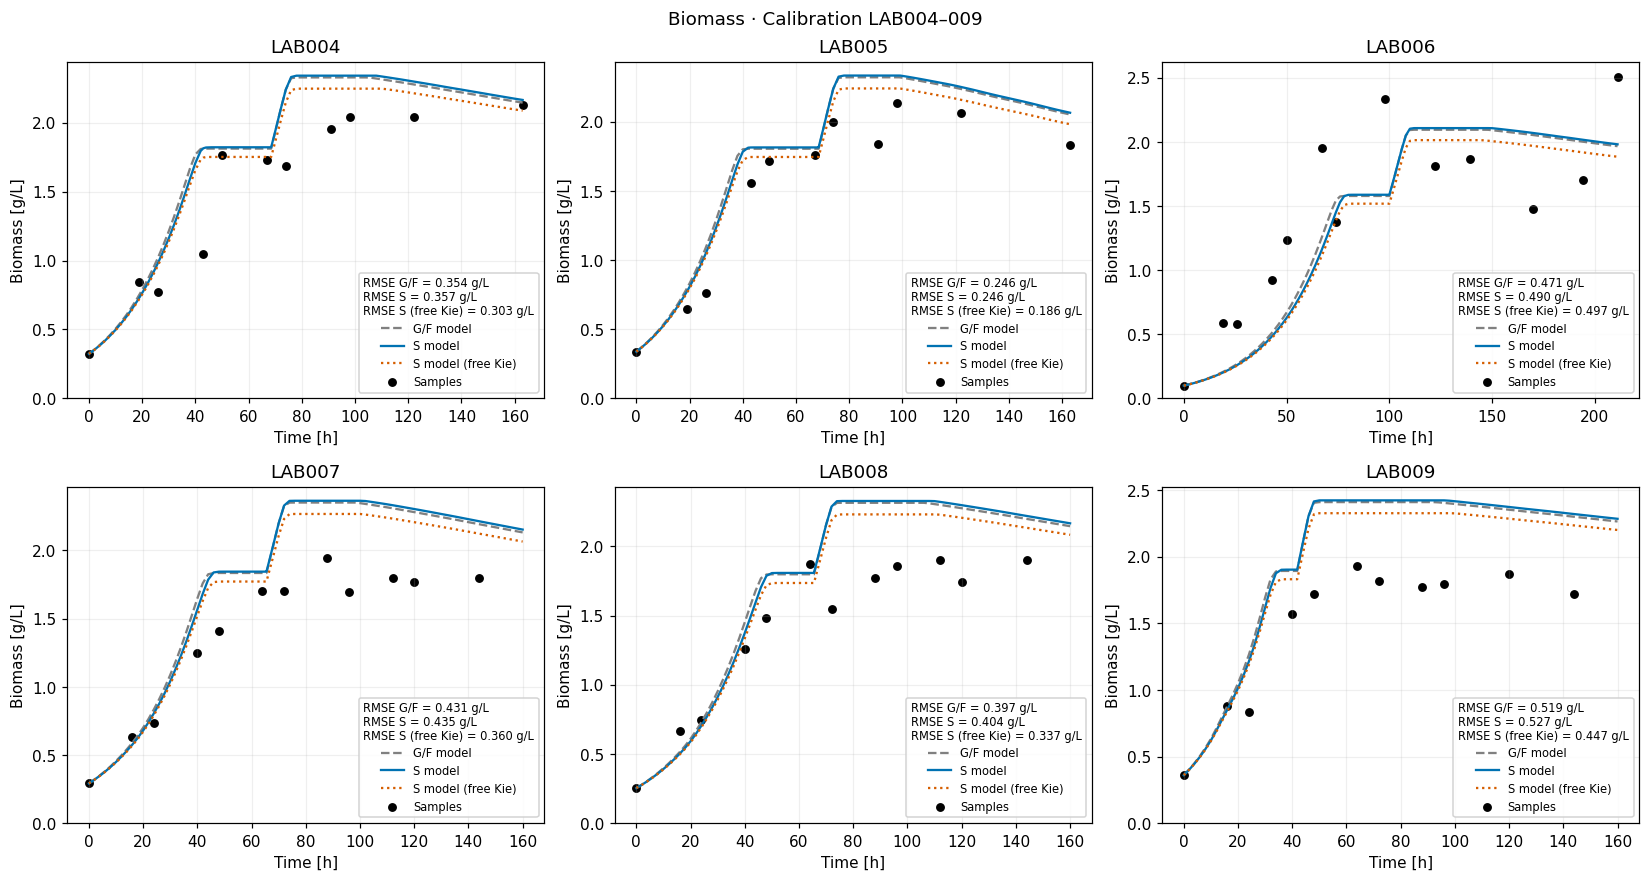

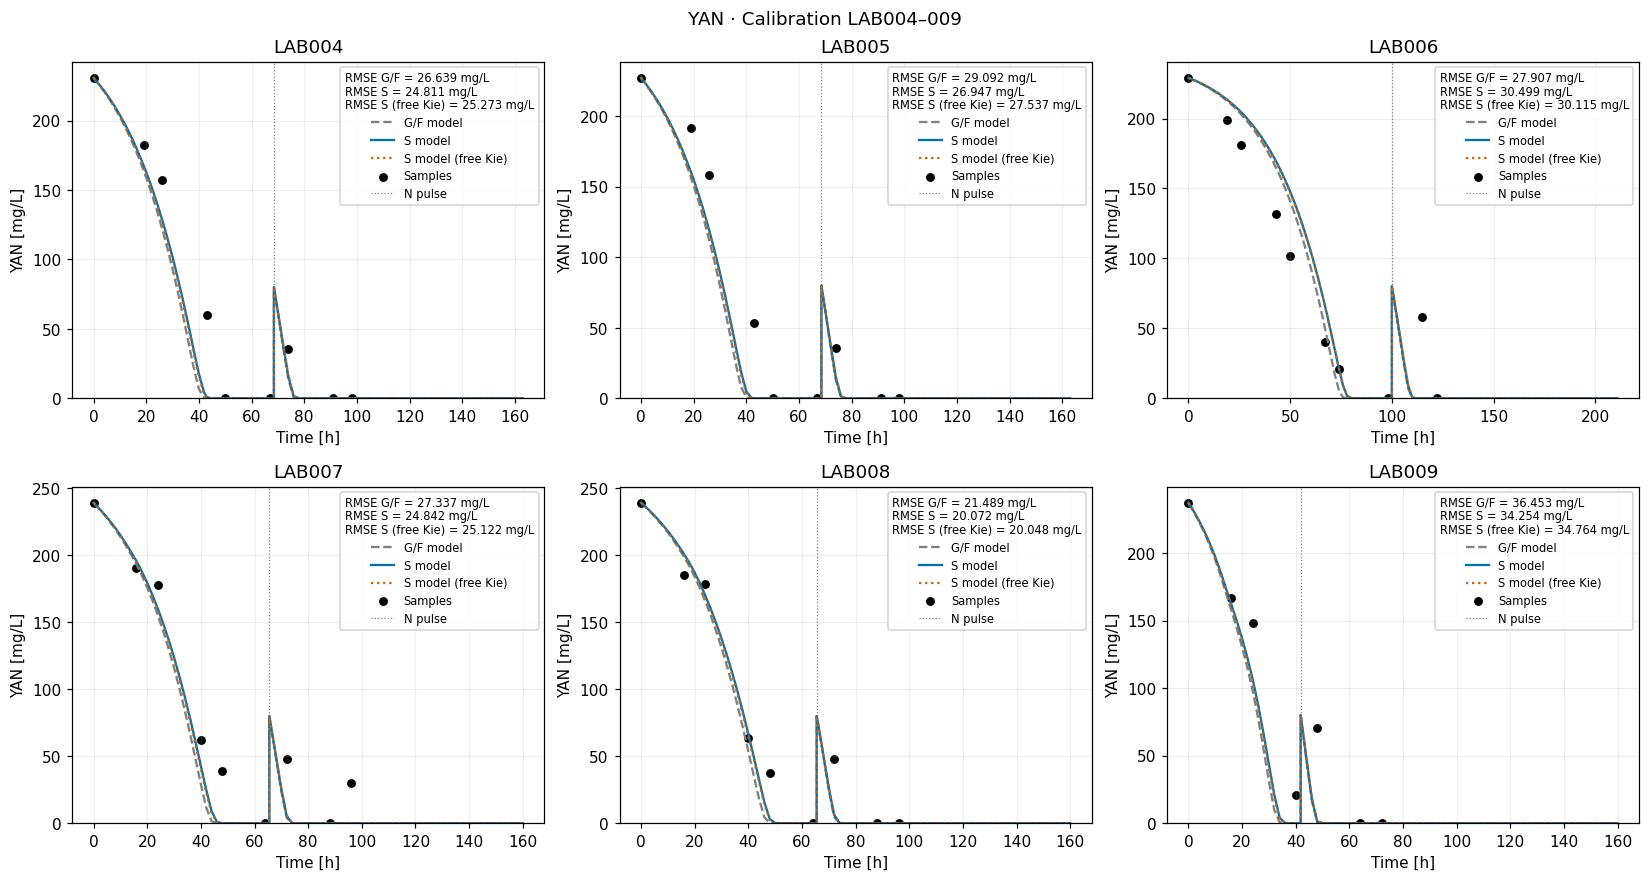

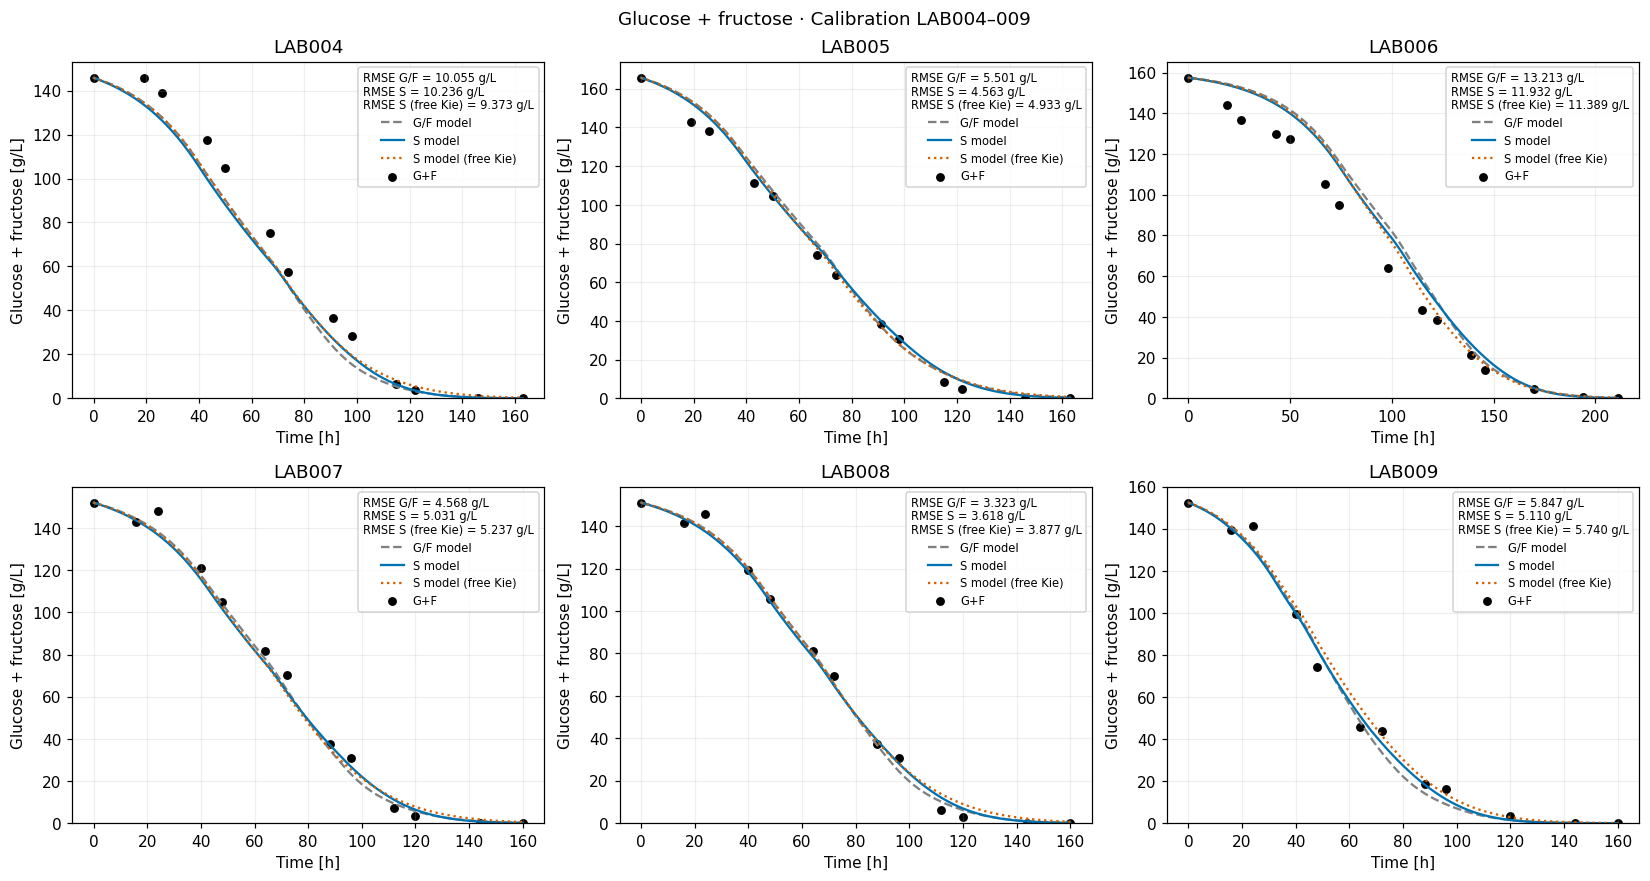

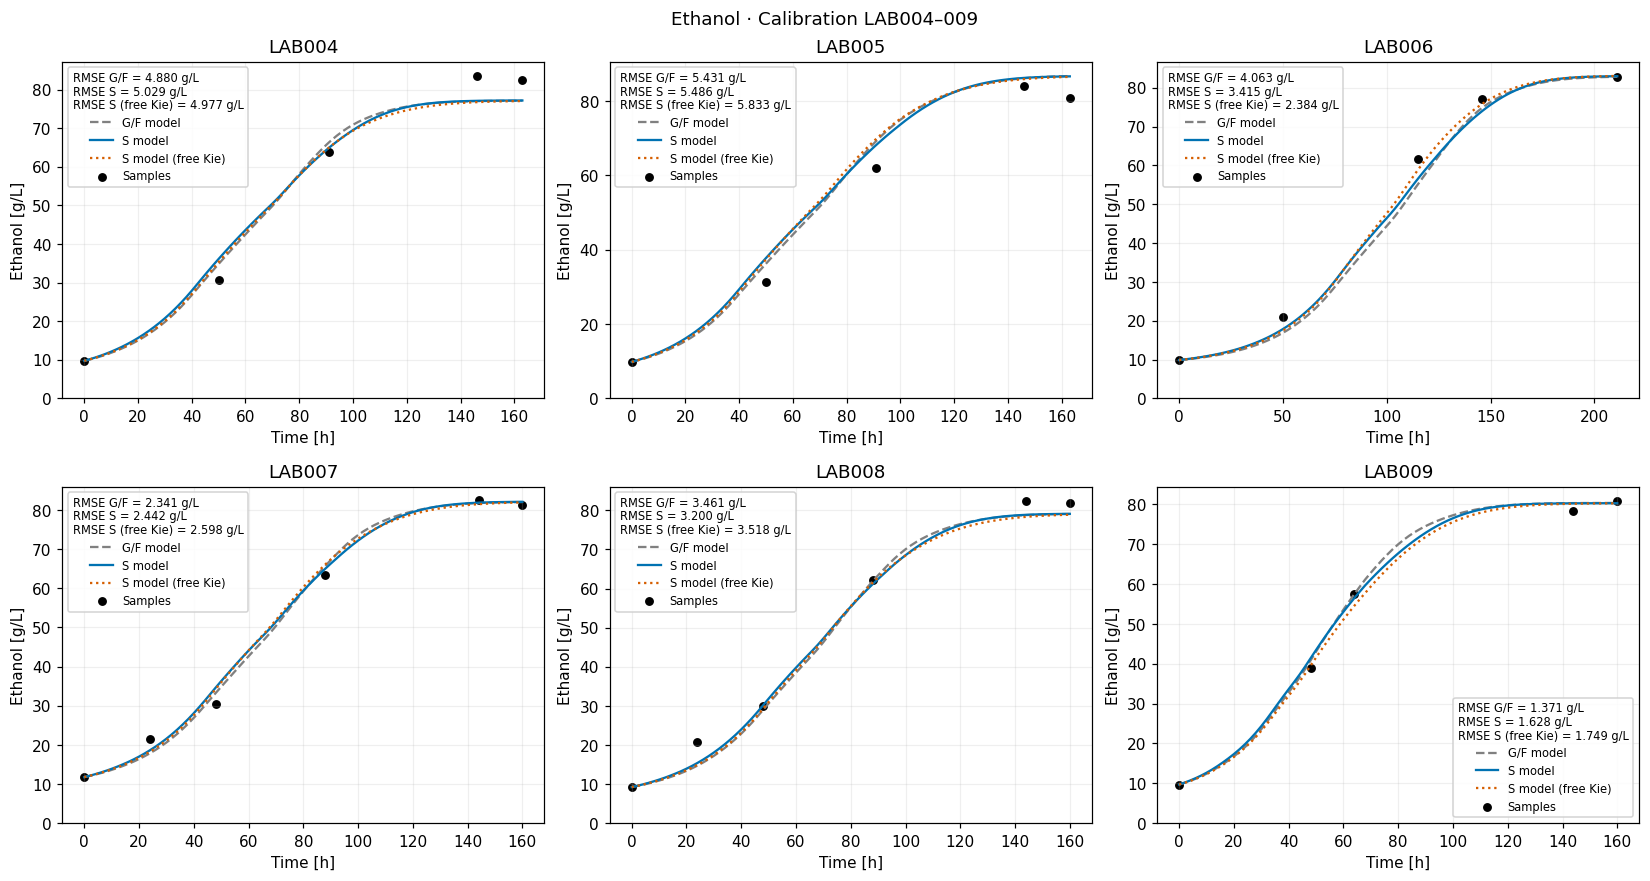

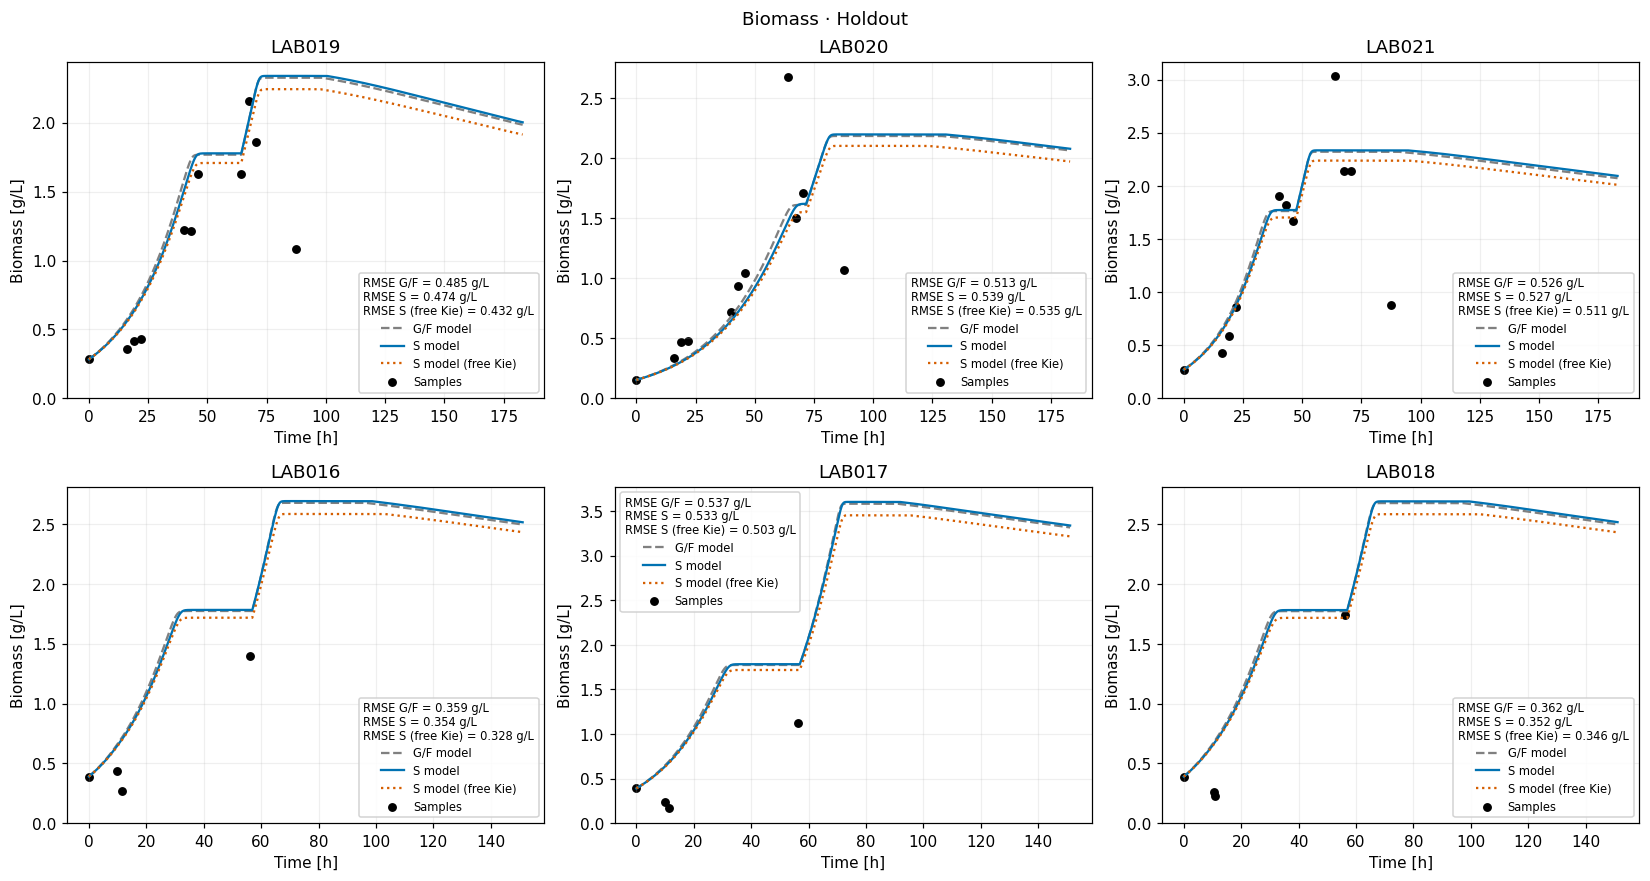

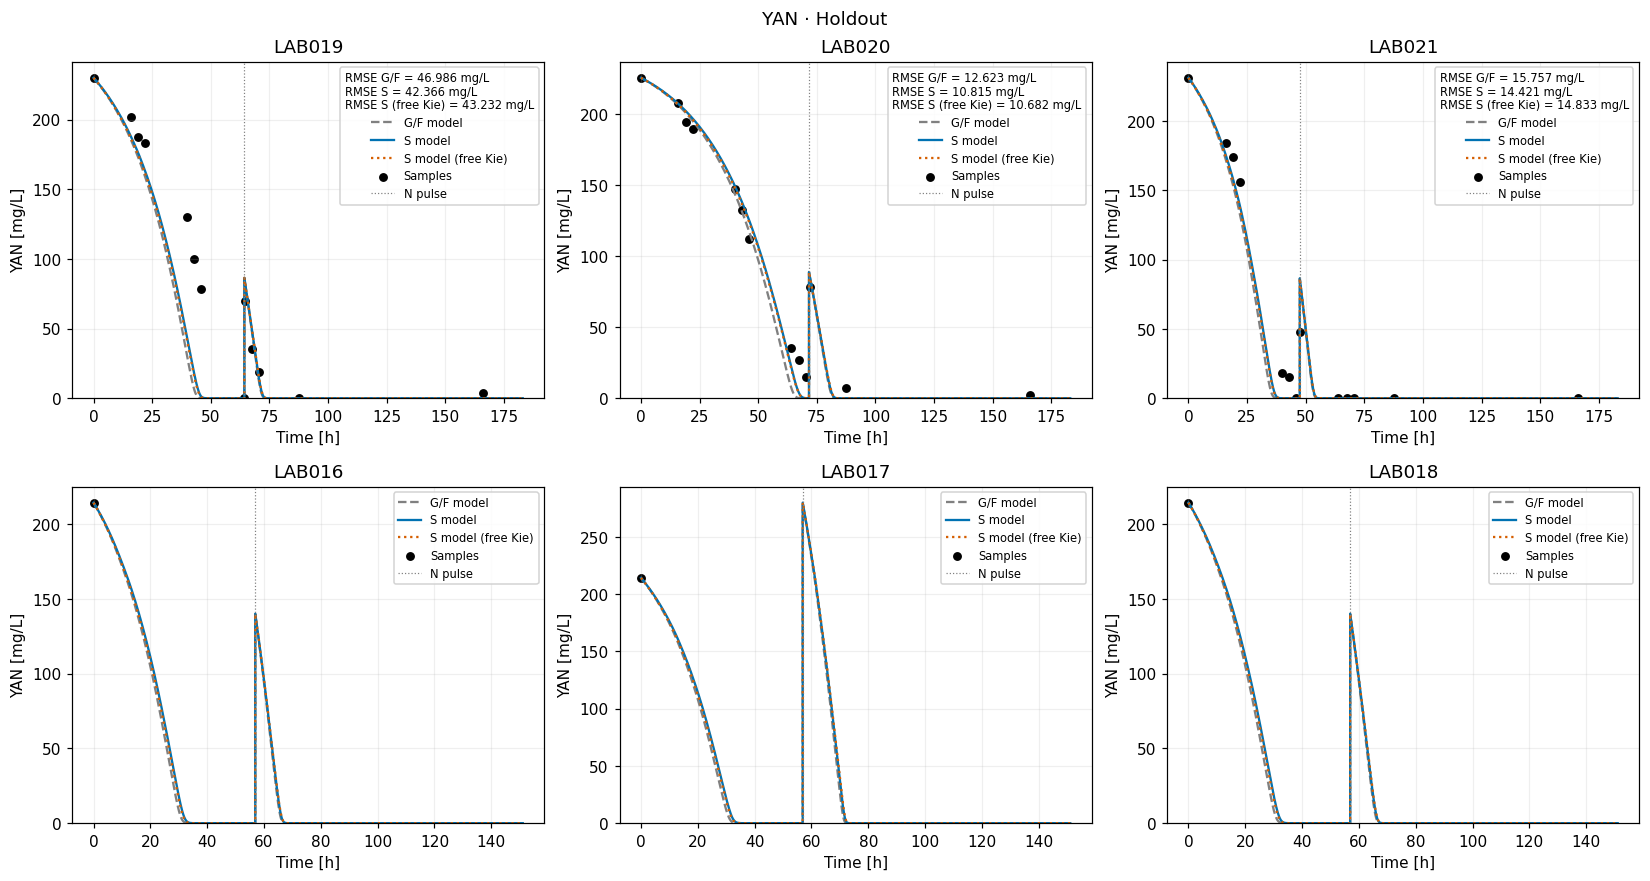

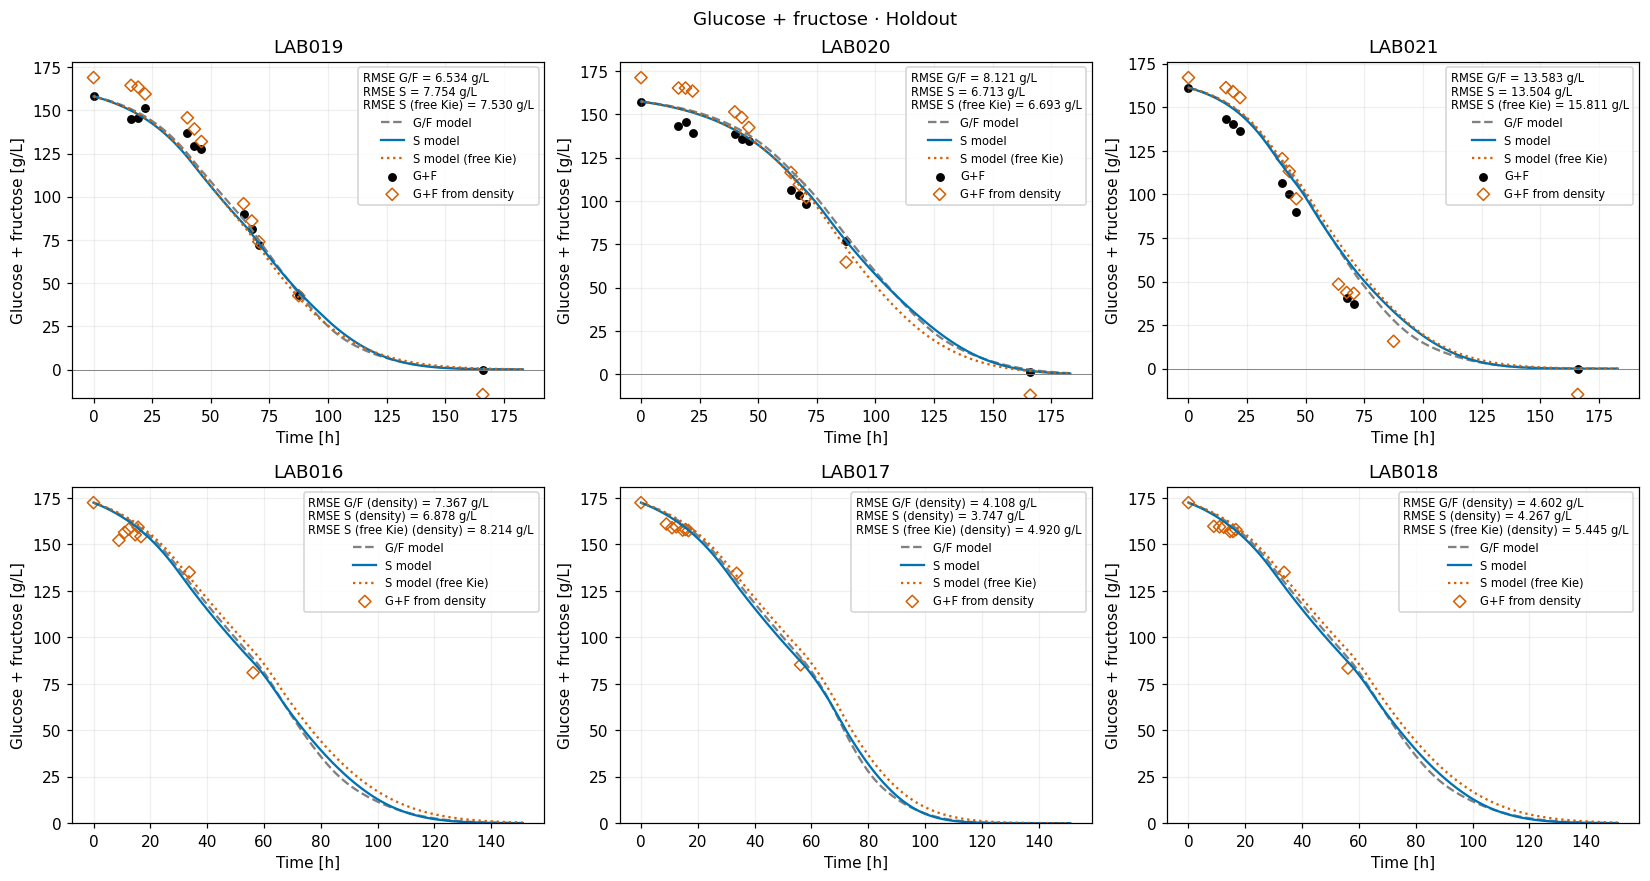

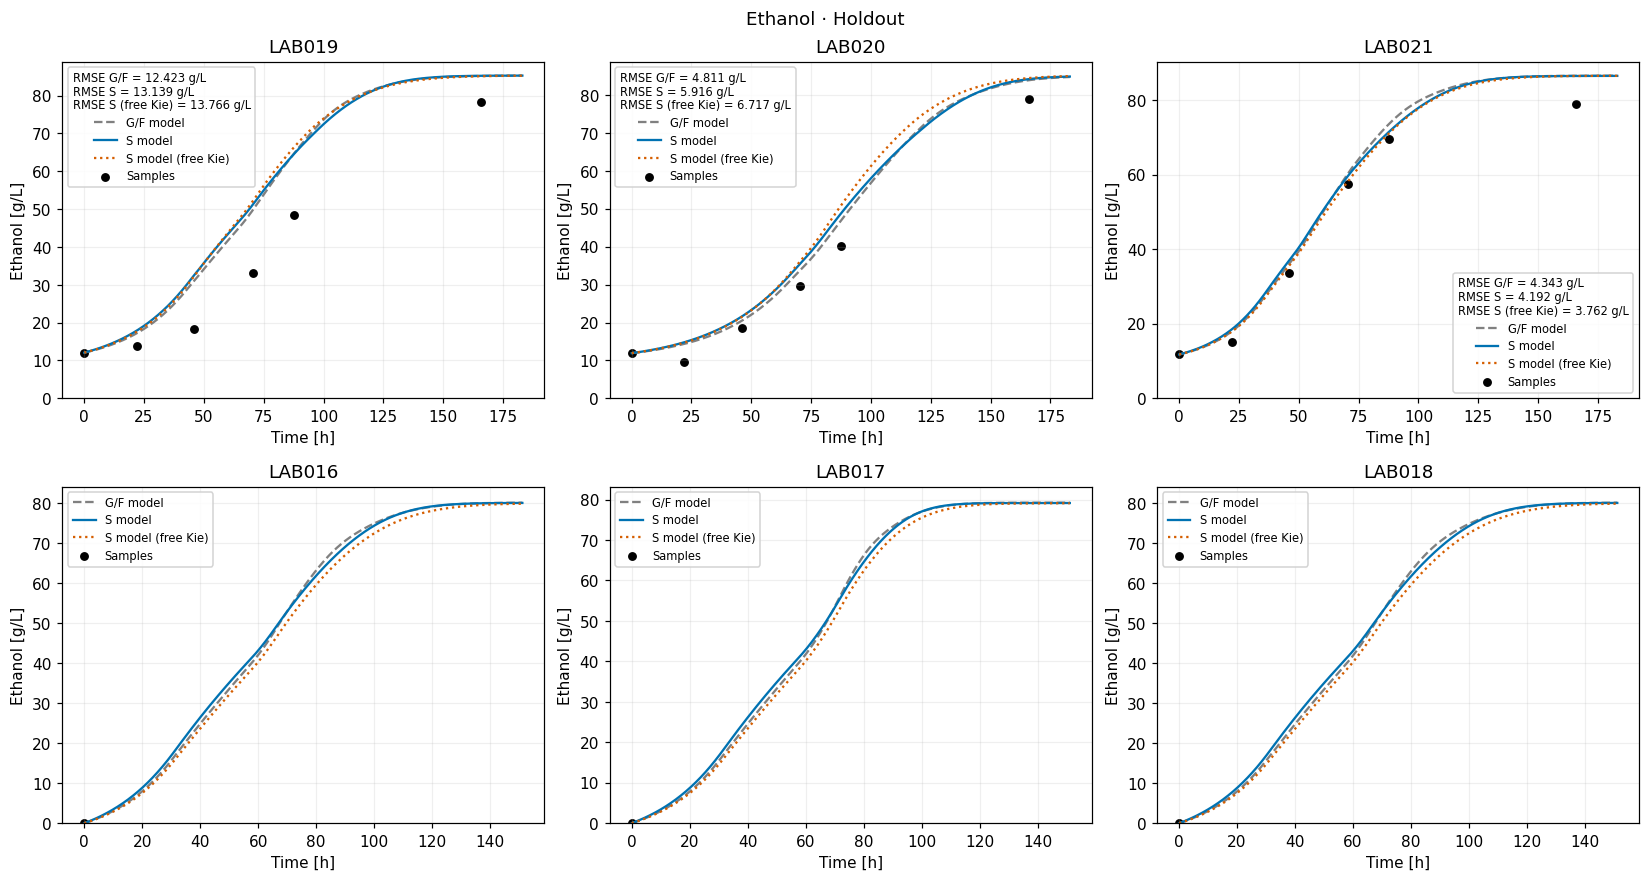

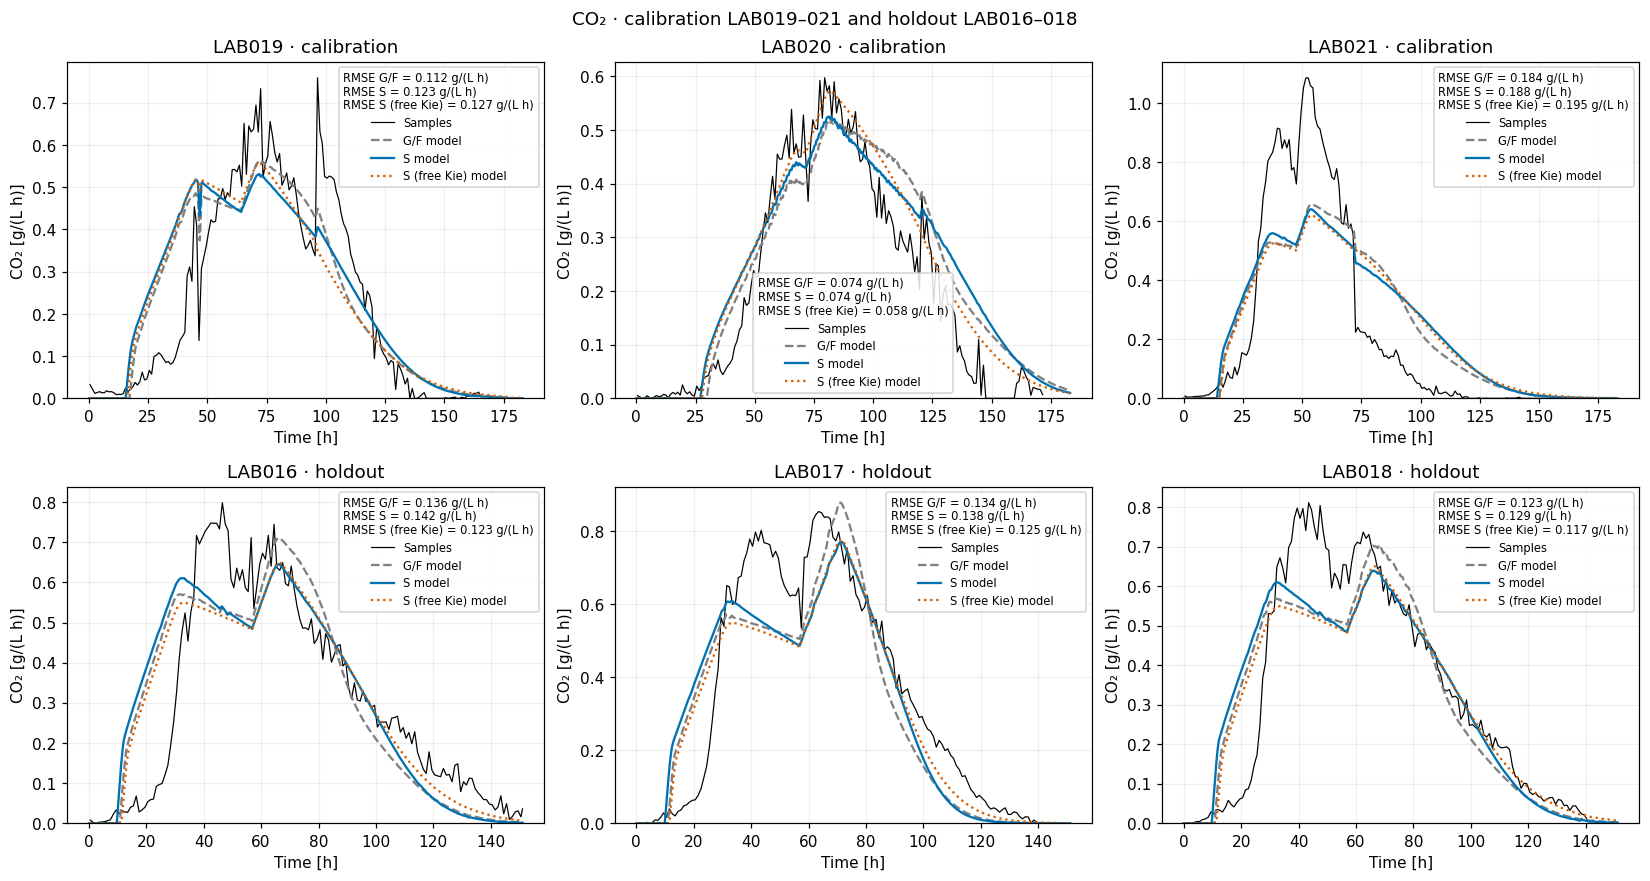

modelo                                    G/F          S  S (free Kie)
rol            LAB    variable n                                      
Calibration    LAB004 E        4     4.879543   5.028815      4.977355
                      N        8    26.638593  24.811488     25.272938
                      S        12   10.055109  10.236389      9.373491
                      X        10    0.353789   0.356708      0.302510
               LAB005 E        4     5.431243   5.485803      5.833423
                      N        8    29.091953  26.946898     27.536677
                      S        12    5.500948   4.562708      4.933043
                      X        10    0.245549   0.246304      0.186047
               LAB006 E        4     4.063489   3.414525      2.383501
                      N        9    27.906597  30.499204     30.114674
                      S        14   13.213141  11.932324     11.389147
                      X        12    0.471184   0.489876      0.496979
               LAB007 E        5     2.340730   2.442421      2.598175
                      N        8    27.336720  24.841771     25.122233
                      S        12    4.567574   5.030904      5.237112
                      X        11    0.430609   0.435457      0.359514
               LAB008 E        5     3.461338   3.200358      3.517730
                      N        8    21.489200  20.071840     20.047621
                      S        12    3.322800   3.617627      3.877070
                      X        11    0.397483   0.404257      0.336737
               LAB009 E        4     1.370620   1.628107      1.748737
                      N        6    36.453395  34.253782     34.763675
                      S        11    5.846610   5.109714      5.740490
                      X        10    0.518544   0.527360      0.447060
Gas evaluation LAB016 CO2      152   0.135665   0.141586      0.122511
               LAB017 CO2      141   0.134385   0.138341      0.125269
               LAB018 CO2      141   0.122654   0.128754      0.117174
               LAB019 CO2      166   0.112240   0.122515      0.127437
               LAB020 CO2      172   0.074421   0.074389      0.057991
               LAB021 CO2      166   0.183502   0.187986      0.195113
Holdout        LAB016 X        3     0.359155   0.354077      0.327789
               LAB017 X        3     0.536581   0.533142      0.503491
               LAB018 X        3     0.362133   0.351884      0.346247
               LAB019 E        5    12.423263  13.138972     13.765961
                      N        12   46.985655  42.366222     43.231868
                      S        11    6.533820   7.753826      7.530278
                      X        10    0.484605   0.473706      0.432214
               LAB020 E        5     4.811317   5.916497      6.717158
                      N        12   12.622841  10.815421     10.681888
                      S        11    8.121471   6.712841      6.692602
                      X        10    0.513404   0.538682      0.535273
               LAB021 E        5     4.343183   4.191579      3.761518
                      N        12   15.757195  14.420748     14.832582
                      S        9    13.583468  13.504035     15.810601
                      X        10    0.526470   0.527217      0.511232

,LAB,model,state,first_time_after_pulse_h,residual
0,LAB004,G/F,S,130.000000,0.063679
1,LAB004,G/F,N,76.000000,0.000000
2,LAB004,S,S,130.000000,0.041412
3,LAB004,S,N,78.000000,0.000000
4,LAB004,S (free Kie),S,140.000000,0.292668
...,...,...,...,...,...
67,LAB018,G/F,N,66.666667,0.000000
68,LAB018,S,S,121.083333,0.042103
69,LAB018,S,N,67.083333,0.000000
70,LAB018,S (free Kie),S,131.416667,0.339240


In [3]:
comparison=[]

def original_state(f,s):return f['GF' if s=='S' else s]

def finish_figure(fig,axs,title):
 fig.suptitle(title,y=.99)
 fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9)
 for ax in axs.flat:
  handles,labels=ax.get_legend_handles_labels();unique=dict(zip(labels,handles))
  legend=ax.legend(unique.values(),unique.keys(),loc='best',fontsize=7.5,framealpha=.85,title=getattr(ax,'_rmse_text',None),title_fontsize=7.5)
  assert len(legend.get_texts())==len(unique)
 assert not fig.legends
 plt.show()

def draw_group(group,reference,reduced,holdout=False):
 for s,title in [('X','Biomass'),('N','YAN'),('S','Glucose + fructose'),('E','Ethanol')]:
  scale=1000 if s=='N' else 1;unit='mg/L' if s=='N' else 'g/L'
  fig,axs=plt.subplots(2,3,figsize=(15,8))
  for ax,item in zip(axs.flat,group):
   b=batches[item] if holdout else item;lab=b.batch;a=with_jumps(reference[lab]);r=plotframe_s(reduced[lab]);u=plotframe_s((free_cores if holdout else free_train)[lab])
   ax.plot(a.index,original_state(a,s)*scale,c='gray',ls='--',label='G/F model')
   ax.plot(r.index,r[s]*scale,c='#0072B2',label='S model')
   ax.plot(u.index,u[s]*scale,c='#D55E00',ls=':',label='S model (free Kie)')
   label='G+F' if s=='S' else 'Samples'
   if not holdout:
    yy,sg,mask=targets(b,s);tt=b.time
    ax.scatter(tt[mask],yy[mask]*scale,c='black',s=23,label=label)
   else:
    col='GF' if s=='S' else s
    if lab in TRAIN:
     z=chemical_observations(v.chem,lab,col);tt=z.t_h.to_numpy();yy=z[CHEMICAL_COLUMNS[col]].to_numpy()
    elif s=='X':
     z=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l']);tt=z.t_h.to_numpy();yy=z.X_viable_g_l.to_numpy()
    else:tt=np.array([]);yy=np.array([])
    mask=np.isfinite(yy)&(tt>0)&(tt<=v.horizons[lab]);shown=np.isfinite(yy)&~np.isclose(tt,0.)
    if shown.any():ax.scatter(tt[shown],yy[shown]*scale,c='black',s=23,label=label)
    if s=='S':
     z=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l'])
     ax.scatter(z.t_h,2.5*(z.density_g_l-1000),marker='D',facecolors='none',edgecolors='#D55E00',s=32,label='G+F from density')
   # Use the actual corrected model initial value, never the superseded biomass observation.
   if not (holdout and s=='S' and lab not in TRAIN):
    initial_point=ax.scatter([0.],[r[s].iloc[0]*scale],c='black',s=23,label=label)
    assert np.allclose(initial_point.get_offsets(),[[0.,r[s].iloc[0]*scale]])
   errors=[]
   for model,f,vals in [('G/F',a,original_state(a,s)),('S',r,r[s]),('S (free Kie)',u,u[s])]:
    if mask.any():
     # Same scoring operator and samples as diagnostic 17.
     err=(np.interp(tt[mask],f.index,vals)-yy[mask])*scale
     value=float(np.sqrt(np.mean(err**2)));errors.append(f'RMSE {model} = {value:.3f} {unit}')
     comparison.append(dict(LAB=lab,rol='Holdout' if holdout else 'Calibration',variable=s,modelo=model,n=int(mask.sum()),RMSE=value,sesgo=float(err.mean())))
   if holdout and s=='S' and not mask.any():
    # Label density-based errors explicitly; do not add them to the chemical scoring table.
    density_mask=z.t_h.gt(0)&z.t_h.le(v.horizons[lab]);dt=z.loc[density_mask,'t_h'].to_numpy();dy=2.5*(z.loc[density_mask,'density_g_l'].to_numpy()-1000)
    for model,f,vals in [('G/F',a,original_state(a,s)),('S',r,r[s]),('S (free Kie)',u,u[s])]:
     if len(dt):errors.append(f'RMSE {model} (density) = {np.sqrt(np.mean((np.interp(dt,f.index,vals)-dy)**2)):.3f} g/L')
   if errors:ax._rmse_text='\n'.join(errors)
   if s=='N':
    for t,d in b.pulses['N']:ax.axvline(t,c='gray',ls=':',lw=.8,label='N pulse')
   ax.set(title=lab,xlabel='Time [h]',ylabel=title+f' [{unit}]',ylim=(0,None));ax.grid(alpha=.2)
   if holdout and s=='S':
    ax.set_ylim(bottom=min(0.,float((2.5*(z.density_g_l-1000)).min())*1.15));ax.axhline(0,c='gray',lw=.6)
  finish_figure(fig,axs,title+' · '+('Holdout' if holdout else 'Calibration LAB004–009'))

draw_group(treated,original_train,reduced_train)
draw_group(LABS,original_cores,reduced_cores,True)
fig,axs=plt.subplots(2,3,figsize=(15,8))
for ax,lab in zip(axs.flat,LABS):
 o=obs[lab];ax.plot(o.time_h,o.co2_raw_g_l_h,c='black',lw=.8,label='Samples');errors=[]
 for model,cur,color,style in [('G/F',original_gas,'gray','--'),('S',reduced_gas,'#0072B2','-'),('S (free Kie)',free_gas,'#D55E00',':')]:
  f=cur[lab];ax.plot(f.index,f.qpred,c=color,ls=style,label=model+' model');err=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h
  value=float(np.sqrt(np.mean(err**2)));errors.append(f'RMSE {model} = {value:.3f} g/(L h)')
  comparison.append(dict(LAB=lab,rol='Gas evaluation',variable='CO2',modelo=model,n=len(o),RMSE=value,sesgo=float(err.mean())))
 ax._rmse_text='\n'.join(errors)
 ax.set(title=lab+(' · calibration' if lab in TRAIN else ' · holdout'),xlabel='Time [h]',ylabel='CO₂ [g/(L h)]',ylim=(0,None));ax.grid(alpha=.2)
finish_figure(fig,axs,'CO₂ · calibration LAB019–021 and holdout LAB016–018')
metrics_s=pd.DataFrame(comparison);display(metrics_s.pivot(index=['rol','LAB','variable','n'],columns='modelo',values='RMSE'));print('METRICS_JSON',metrics_s.to_json(orient='records'))

timing=[]
for lab,f in {**reduced_train,**reduced_cores}.items():
 a=original_train.get(lab,original_cores.get(lab))
 for model,frame in [('G/F',a),('S',f),('S (free Kie)',free_train.get(lab,free_cores.get(lab)))]:
  for state,threshold in [('S',2.),('N',.001)]:
   values=original_state(frame,state) if model=='G/F' else frame[state];lastpulse=max(t for t,d in (bylab.get(lab,batches.get(lab))).pulses['N']);ids=np.flatnonzero((frame.index>lastpulse)&(values<=threshold))
   timing.append(dict(LAB=lab,model=model,state=state,first_time_after_pulse_h=float(frame.index[ids[0]]) if len(ids) else np.nan,residual=float(values.iloc[-1])))
display(pd.DataFrame(timing))
assert set(metrics_s.modelo)=={'G/F','S','S (free Kie)'}
assert ps['Kie0']==original_theta['Kie0']
assert theta==original_theta and theta['Kd0']==.00044 and np.isclose(theta['Kn0']*KN_THERMAL_FACTOR,.01)
assert GAS_BOUNDS['kLa'][0]<=KLA<=GAS_BOUNDS['kLa'][1] and GAS_BOUNDS['gain'][0]<=GAIN<=GAS_BOUNDS['gain'][1]
for lab,f in reduced_cores.items():
 for t,bef,aft in f.attrs['jumps']:assert np.array_equal(bef[[0,2,3]],aft[[0,2,3]])
for p,h in hashes.items():assert hashlib.sha256(p.read_bytes()).hexdigest()==h,str(p)
print('Previous files unchanged. No fitting on holdout samples.')


## Scope
Chemical equations and preprocessing are inherited from the original. The variable-solubility equations, assumptions and gas-only calibration below supersede the previous gas formulation. All reported gas results are recomputed.

In [4]:
display(pd.DataFrame(gas_fits.values()))
print('ALL_GAS_FITS_JSON',json.dumps(gas_fits))


ALL_GAS_FITS_JSON {"G/F": {"model": "G/F", "kLa": 0.15007991020720535, "gain": 0.6460643588058115, "training_MSE": 0.017269820343074855, "training": ["LAB019", "LAB020", "LAB021"], "holdout": ["LAB016", "LAB017", "LAB018"], "kLa_at_bound": false, "gain_at_bound": false}, "S": {"model": "S", "kLa": 0.13796553316180868, "gain": 0.6586783889606775, "training_MSE": 0.018627427255287904, "training": ["LAB019", "LAB020", "LAB021"], "holdout": ["LAB016", "LAB017", "LAB018"], "kLa_at_bound": false, "gain_at_bound": false}, "S alternative": {"model": "S alternative", "kLa": 0.14738417435212173, "gain": 0.643833492674196, "training_MSE": 0.01922407924806257, "training": ["LAB019", "LAB020", "LAB021"], "holdout": ["LAB016", "LAB017", "LAB018"], "kLa_at_bound": false, "gain_at_bound": false}}


,model,kLa,gain,training_MSE,training,holdout,kLa_at_bound,gain_at_bound
0,G/F,0.150080,0.646064,0.017270,"[LAB019, LAB020, LAB021]","[LAB016, LAB017, LAB018]",False,False
1,S,0.137966,0.658678,0.018627,"[LAB019, LAB020, LAB021]","[LAB016, LAB017, LAB018]",False,False
2,S alternative,0.147384,0.643833,0.019224,"[LAB019, LAB020, LAB021]","[LAB016, LAB017, LAB018]",False,False
